# Step 4 — "Why not?" module (deal breakers, complaints, alternatives)

Runs `src/why_not/why_not.py` on the real Electronics knowledge base.

**Runtime:** GPU recommended (*Runtime → Change runtime type → T4 GPU*), CPU also works but sentiment is slower.

Sections:
1. Setup (Drive, code, libraries, data)
2. Load the explainer
3. Try one product
4. Batch run on products from the 20 formal queries (saved for the report + evaluation)
5. Sanity check: do deal breakers line up with lower average ratings?
6. Export a sample for human checking (precision of deal breakers / alternatives)


## 1. Setup


In [1]:
from google.colab import drive
drive.mount('/content/drive')

# Your own Drive folder for saving outputs and caches (created if missing)
OUT_DIR = "/content/drive/MyDrive/why_not_work"
import os; os.makedirs(OUT_DIR, exist_ok=True)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Get the team code (retrieval + why_not)
import os, shutil
if not os.path.exists("/content/repo"):
    !git clone -q https://github.com/Nariassa/ShopSmart-Advisor---An-Evidence-Based-Online-Shopping-Agent-AI6127-GP-.git /content/repo
%cd /content/repo

# Until why_not is on GitHub, upload your latest why_not.py here every time you change it.
UPLOAD_WHY_NOT = True
if UPLOAD_WHY_NOT:
    from google.colab import files
    os.makedirs("src/why_not", exist_ok=True)
    open("src/why_not/__init__.py", "a").close()
    print("Upload why_not.py now")
    for name, data in files.upload().items():
        open("src/why_not/why_not.py", "wb").write(data)   # saved under the right name even if renamed "why_not (1).py"
!ls -l src/why_not


/content/repo
Upload why_not.py now


Saving why_not.py to why_not (4).py
total 40
-rw-r--r-- 1 root root     0 Oct 27 10:16 __init__.py
drwxr-xr-x 2 root root  4096 Oct 27 12:05 __pycache__
-rw-r--r-- 1 root root 35871 Oct 27 12:13 why_not.py


In [3]:
!pip install -q chromadb sentence-transformers rank-bm25 transformers pyarrow scipy gdown openpyxl
# A red "pip's dependency resolver" warning about google-adk / opentelemetry is harmless - ignore it.


In [4]:
# Find the knowledge base: (1) anywhere in your Drive, else (2) download it
# with the same Google Drive file id the team's download_kb.py uses.
import glob, shutil, json, zipfile

def find_in_drive(name):
    # look up to 3 folders deep (a full-Drive search can take very long)
    for root in ["/content/drive/MyDrive", "/content/drive/Shareddrives"]:
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            hits = glob.glob(f"{root}/{depth}{name}")
            if hits:
                return hits[0]
    return None

CHUNKS = "/content/chunks.parquet"
if not os.path.exists(CHUNKS):
    src = find_in_drive("chunks.parquet")
    if src:
        print("Found in Drive:", src); shutil.copy(src, CHUNKS)
    else:
        manifest = json.load(open("download_manifest.json"))
        file_id = next(f["id"] for f in manifest["files"] if f["name"] == "chunks.parquet")
        print("Not in your Drive - downloading with gdown ...")
        !gdown --fuzzy "https://drive.google.com/uc?id={file_id}" -O {CHUNKS}

# Chroma is optional: without it, alternatives use title similarity instead.
CHROMA = None
if os.path.isdir("/content/chroma_db"):
    CHROMA = "/content/chroma_db"
else:
    z = find_in_drive("chroma_db.zip")
    if z:
        print("Found Chroma zip:", z)
        with zipfile.ZipFile(z) as zf: zf.extractall("/content")
        CHROMA = "/content/chroma_db"
print("chunks.parquet:", f"{os.path.getsize(CHUNKS)/1e9:.2f} GB" if os.path.exists(CHUNKS) else "MISSING")
print("Chroma index:  ", CHROMA or "not available -> using title similarity for alternatives")


chunks.parquet: 0.84 GB
Chroma index:   not available -> using title similarity for alternatives


## 2. Load the explainer
Loads 4.45M chunks (~1–3 min) and the sentiment model. The first time without Chroma, it also embeds one title per product for finding alternatives and saves them to your Drive, so later runs skip that step.


In [5]:
import time, json
from IPython.display import Markdown, display
from src.why_not.why_not import WhyNotExplainer, to_markdown

t = time.time()
explainer = WhyNotExplainer.from_paths(
    CHUNKS,
    chroma_path=CHROMA,
    title_cache=f"{OUT_DIR}/title_vectors.npz",   # built once (~few min on GPU), reused afterwards
)
print(f"Loaded in {time.time() - t:.1f}s")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Alternatives: title similarity over 198,592 products


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loaded in 33.0s


## 3. Try one product
`B0764GNRDZ` is the top Dense result for test query Q001 (earbuds for long flights).


In [6]:
result = explainer.explain(
    "B0764GNRDZ",
    query="Which wireless earbuds have long battery life and stay comfortable during long flights?",
)
display(Markdown(to_markdown(result)))
print(f"latency: {result['latency_seconds']}s")


### ⚠️ Why not *JBL Everest 310 On-Ear Wireless Bluetooth Headphones (Purple)*?
No deal breakers or major complaints in 14 review chunks; 4 negative mention(s), listed below as minor concerns.

🔸 **Minor concern (design/appearance, 1 mention(s)):** "These are horrible when turned all the way up, lots of static which was disappointing because I love the color." `[B0764GNRDZ_review_3138069]`
🔸 **Minor concern (customer service, 1 mention(s)):** "Unfortunately, these will be returned As Soon As Possible!" `[B0764GNRDZ_review_3138070]`
🔸 **Minor concern (other, 2 mention(s)):** "I was hoping I got a bad pair and could send them back for a new pair but I have read some YouTube reviews and others have made the same observation. These are no better than a $30 pair of headphones. I really do not…" `[B0764GNRDZ_review_3138071]`

latency: 0.291s


In [7]:
# The raw JSON the UI / PCS will receive
print(json.dumps(result, indent=2)[:3000])


{
  "asin": "B0764GNRDZ",
  "title": "JBL Everest 310 On-Ear Wireless Bluetooth Headphones (Purple)",
  "category": "Computers",
  "avg_rating": 4.1,
  "query": "Which wireless earbuds have long battery life and stay comfortable during long flights?",
  "required_aspects": [
    "battery life",
    "comfort"
  ],
  "review_chunks_analysed": 14,
  "negative_share_overall": 0.286,
  "deal_breakers": [],
  "complaints": [],
  "polarized": [],
  "missing": [],
  "aspect_summary": {
    "battery life": {
      "chunks": 3,
      "positive": 3,
      "neutral": 0,
      "negative": 0
    },
    "comfort": {
      "chunks": 2,
      "positive": 1,
      "neutral": 1,
      "negative": 0
    },
    "customer service": {
      "chunks": 1,
      "positive": 0,
      "neutral": 0,
      "negative": 1
    },
    "design/appearance": {
      "chunks": 2,
      "positive": 1,
      "neutral": 0,
      "negative": 1
    },
    "price/value": {
      "chunks": 1,
      "positive": 1,
      "neutral":

In [8]:
import random,torch
random.seed(7)
found = None
for n, a in enumerate(random.sample(list(explainer.store._rows.keys()), 400), 1):
    r = explainer.explain(a, with_alternatives=False)
    if r.get("deal_breakers"):
        found = a
        break
print(f"checked {n} products ->", found)
if found:
    result_db = explainer.explain(found)
    display(Markdown(to_markdown(result_db)))
    print(f"latency: {result_db['latency_seconds']}s")
print("GPU:", torch.cuda.is_available())
print(result_db["timing"])

checked 12 products -> B07B1TKSQ9


### ⚠️ Why not *Mcdodo Nylon AUX Adapter 3.5mm, 2018 Premium & Luxury 2in1 Audio Charging Cable (1.2m) for iPhone X/ 8/8 Plus/ 7/7 Plus (Silver)*?
1 deal breaker(s) found in 7 review chunks - most reported: stopped working (2 reports).

🔴 **Deal breaker: stopped working** - reported in 2 of 7 review chunks
> "Zero stars. Just received and aux cord DOES NOT WORK!" `[B07B1TKSQ9_review_3584345]`
> "Terrible! Quit working after a few uses. Had to hold in the correct angle for it to play" `[B07B1TKSQ9_review_3584351]`

✅ **Similar products without this problem:**
- **loiog Aux Cable for Car for iPhone X/XS/8/8Plus/7/7Plus Jack to 3.5mm Male Audio Adapter for Headphones Jack Cable Aux Cord for Car Stereo, Headphone, Speaker** - 0 of 16 review chunks report *stopped working*, rated 4.1★: "Great Product it has lasted me more than a year and it still in good shape. I most of the times carry it in my pocket and still like new even though I have droped it several times from pocket distance." `[B005BP9WAI_review_1277679]`
- **Aux Cord for iPhone,3.5mm Aux Cable for iPhone 7/X/8/8 Plus/XS Max/XR to Car Stereo or Speaker or Headphone Adapter, Support The Newest iOS 11.4/12 Version or Above** - 0 of 25 review chunks report *stopped working*, rated 4.0★

🔸 **Minor concern (price/value, 1 mention(s)):** "Total waste of my money and time." `[B07B1TKSQ9_review_3584346]`
🔸 **Minor concern (battery life, 1 mention(s)):** "the wire stopped charging within 3 days..." `[B07B1TKSQ9_review_3584349]`
🔸 **Minor concern (other, 1 mention(s)):** "Would give it zero stars if I could...." `[B07B1TKSQ9_review_3584348]`

latency: 0.531s
GPU: True
{'analysis': 0.001, 'similar_search': 0.175, 'alternatives': 0.355}


## 4. Batch run on the formal test queries
For each of the 20 formal queries, take the top 3 distinct products from the saved Dense run and explain them.


In [10]:
import pandas as pd

queries = [json.loads(l) for l in open("results/formal_dense_results.jsonl")]
jobs = []
for q in queries:
    seen = []
    for r in q["results"]:
        if r["parent_asin"] not in seen:
            seen.append(r["parent_asin"])
        if len(seen) == 3:
            break
    jobs += [(q["query_id"], q["query"], asin) for asin in seen]
print(len(jobs), "product explanations to run")

os.makedirs("results", exist_ok=True)
outputs = []
for qid, query, asin in jobs:
    r = explainer.explain(asin, query=query)
    r["query_id"] = qid
    outputs.append(r)
    print(qid, asin, "|", r.get("headline", r.get("error")), f"({r.get('latency_seconds')}s)")

with open("results/why_not_formal_results.jsonl", "w") as f:
    for r in outputs:
        f.write(json.dumps(r) + "\n")


60 product explanations to run
Q001 B0764GNRDZ | No deal breakers or major complaints in 14 review chunks; 4 negative mention(s), listed below as minor concerns. (0.001s)
Q001 B072HKMXWL | No deal breakers in 29 review chunks; main complaint: connectivity. (0.003s)
Q001 B071HLZ9S3 | No deal breakers or major complaints found in 10 review chunks. (0.0s)
Q002 B00N43BPPO | No deal breakers in 58 review chunks; main complaint: connectivity. (0.004s)
Q002 B00OGUVGYE | No deal breakers in 45 review chunks; main complaint: connectivity. (0.001s)
Q002 B00ECGRODE | No deal breakers in 65 review chunks; main complaint: build quality. (0.006s)
Q003 B01N4NY1KE | No deal breakers or major complaints in 29 review chunks; 3 negative mention(s), listed below as minor concerns. (0.001s)
Q003 B008R523N2 | No deal breakers in 75 review chunks; main complaint: battery life. (0.005s)
Q003 B00FAYDU12 | No deal breakers in 43 review chunks; main complaint: comfort. (0.002s)
Q004 B0B1YLJZTK | No deal breakers

In [11]:
# Performance numbers for the report (Q4: latency / throughput)
lat = pd.Series([r["latency_seconds"] for r in outputs if "latency_seconds" in r])
print(lat.describe(percentiles=[.5, .95]).round(3))
print(f"Products explained per second: {1 / lat.mean():.2f}")
print("Products with >=1 deal breaker:", sum(bool(r.get("deal_breakers")) for r in outputs), "/", len(outputs))
print("Deal breakers with >=1 alternative:",
      sum(bool(d["alternatives"]) for r in outputs for d in r.get("deal_breakers", [])), "/",
      sum(len(r.get("deal_breakers", [])) for r in outputs))


count    60.000
mean      0.445
std       0.465
min       0.000
50%       0.272
95%       1.275
max       1.645
dtype: float64
Products explained per second: 2.25
Products with >=1 deal breaker: 11 / 60
Deal breakers with >=1 alternative: 8 / 13


## 5. Sanity check (no labelling needed)
If the module finds real problems, products with more deal breakers / a higher negative share
should have a **lower average Amazon rating**. We test this on random products with a Spearman correlation.
Alternatives are switched off here to keep it fast.


In [12]:
import random
from scipy.stats import spearmanr

random.seed(42)
asins = random.sample(list(explainer.store._rows.keys()), 300)
rows = []
for a in asins:
    r = explainer.explain(a, with_alternatives=False)
    if r.get("avg_rating") is None or r["review_chunks_analysed"] < 5:
        continue
    rows.append({"asin": a, "avg_rating": r["avg_rating"],
                 "deal_breakers": len(r["deal_breakers"]),
                 "negative_share": r["negative_share_overall"]})
sanity = pd.DataFrame(rows)
print(len(sanity), "products")
for col in ["deal_breakers", "negative_share"]:
    rho, p = spearmanr(sanity[col], sanity["avg_rating"])
    print(f"{col:15s} vs avg_rating: Spearman rho = {rho:.3f} (p = {p:.2g})")
sanity.to_csv("results/why_not_sanity_check.csv", index=False)


291 products
deal_breakers   vs avg_rating: Spearman rho = -0.157 (p = 0.0074)
negative_share  vs avg_rating: Spearman rho = -0.396 (p = 2.2e-12)


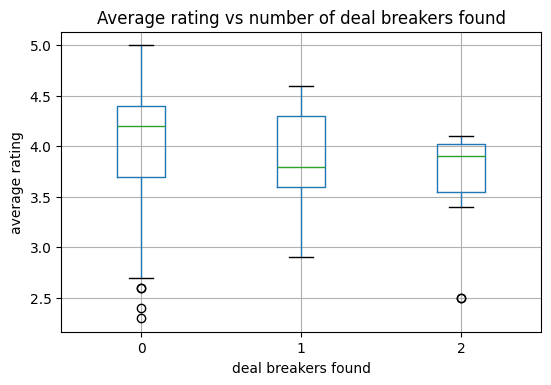

In [13]:
import matplotlib.pyplot as plt
sanity.boxplot(column="avg_rating", by="deal_breakers", figsize=(6, 4))
plt.title("Average rating vs number of deal breakers found"); plt.suptitle("")
plt.xlabel("deal breakers found"); plt.ylabel("average rating")
plt.savefig("results/why_not_sanity_check.png", dpi=150, bbox_inches="tight"); plt.show()


## 6. Export for human checking
Gives the evaluation teammate one row per flagged item. Annotators fill `correct` with 1/0:
- deal breaker evidence: does the quote really report this severe issue?
- alternative evidence: does the quote really praise this aspect?

Two annotators label the same file → agreement can be reported.


In [17]:
check = []
for r in outputs:
    for d in r.get("deal_breakers", []):
        for e in d["evidence"]:
            check.append({"type": "deal_breaker", "query_id": r["query_id"], "asin": r["asin"],
                          "claim": f"reports: {d['issue']}", "chunk_id": e["chunk_id"], "quote": e["quote"],
                          "annotator_1": "", "annotator_2": ""})
        for alt in d["alternatives"]:
            e = alt.get("evidence")
            if not e:          # "no_reports" alternative without a quote: nothing to check by reading
                continue
            check.append({"type": "alternative", "query_id": r["query_id"], "asin": alt["asin"],
                          "claim": f"praises: {alt['aspect']}", "chunk_id": e["chunk_id"],
                          "quote": e["quote"], "annotator_1": "", "annotator_2": ""})
check_df = pd.DataFrame(check).drop_duplicates("chunk_id")
check_df.to_excel("results/why_not_human_check.xlsx", index=False)
print(len(check_df), "items to check")
print(check_df["type"].value_counts())
check_df.head()

36 items to check
type
deal_breaker    26
alternative     10
Name: count, dtype: int64


,type,query_id,asin,claim,chunk_id,quote,annotator_1,annotator_2
0,deal_breaker,Q007,B07XW2X742,reports: overheating / safety,B07XW2X742_review_2289095,This laptop is way too expensive to be overhea...,,
1,deal_breaker,Q007,B07XW2X742,reports: overheating / safety,B07XW2X742_review_2289094,I cannot even play The Sims on this laptop for...,,
2,alternative,Q007,B0821892JY,praises: build quality,B0821892JY_review_2182252,Decent let travel with near zero flex. The bui...,,
3,alternative,Q007,B08DHY3VF6,praises: build quality,B08DHY3VF6_review_1762709,"The trackpad is fluid and more than usable, an...",,
4,deal_breaker,Q009,B00A8CH5DU,reports: stopped working,B00A8CH5DU_review_3224787,Could not keep the app store and downloads on ...,,


In [18]:
# Save outputs to your Drive so nothing is lost when Colab resets
for f in ["why_not_formal_results.jsonl", "why_not_sanity_check.csv",
          "why_not_sanity_check.png", "why_not_human_check.xlsx"]:
    if os.path.exists(f"results/{f}"):
        shutil.copy(f"results/{f}", OUT_DIR)
print("Saved to", OUT_DIR)


Saved to /content/drive/MyDrive/why_not_work
